# Autoencoder

### prompt
```prompt
Autoencoderとは？
```

### answer
Autoencoder（オートエンコーダ）は、データの圧縮（次元削減）と再構成を目的とするニューラルネットワークです。主に特徴抽出や異常検知、画像ノイズ除去などに使われます。

---

#### 基本構造

Autoencoder は以下の 2 つの部分から構成されます。

##### 1. Encoder（エンコーダ）

* 入力データ（例：画像）を受け取り、**小さな次元の潜在表現（潜在変数, latent vector）** に圧縮します。
* 例

  $$
  28 \times 28 \text{ の画像} \rightarrow 32 \text{ 次元のベクトル}
  $$

（注意：28 $\times$ 28=784）

##### 2. Decoder（デコーダ）

* 潜在表現を元にして、**元のデータを再構成（復元）** します。
* 目的は、元の入力と復元された出力の差（再構成誤差）を最小にすること。

---

全体として

$$
\text{入力} \rightarrow \text{圧縮} \rightarrow \text{復元}
$$

という処理を行います。

図で示すと以下です。

![](fig/8200-autoencoder-latent.jpg)


## ChatGPTを用いた画像解析例

物質例でなく、scikit-learnに含まれる手書き文字データを用います。
このデータはよく知られており、例が多い方がChatGPTがコードを生成しやすいという理由です。
まずデータを表示します。

### prompt
```prompt
scikitの手書き文字を表示するコードを書いてください。
```


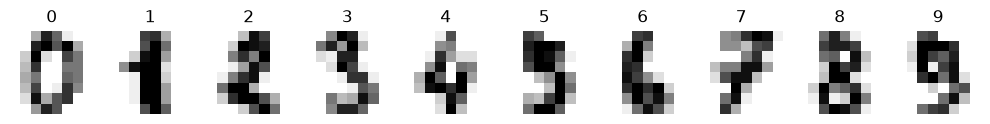

In [1]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# digitsデータセットの読み込み
digits = load_digits()

# 表示する画像数（例として最初の10枚を表示）
n_images = 10

# サブプロットの作成
fig, axes = plt.subplots(1, n_images, figsize=(10, 2))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(str(label))
    ax.axis('off')  # 軸を非表示にする

plt.tight_layout()
plt.show()


このデータは（数字ラベル、数字イメージ）と組になっています。
数字ラベルは0から9までの数字がついています。

例として数字0の画像を抽出し表示させます。

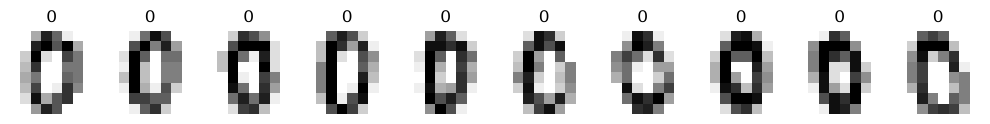

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# digitsデータセットの読み込み
digits = load_digits()

# 表示する画像数（例として最初の10枚を表示）
n_images = 10
target = 0  # 例として数字0の画像を抽出

# 指定したターゲットのインデックスを取得
index = []
for i, label in enumerate(digits.target):
    if label == target:
        index.append(i)
    if len(index) >= n_images:
        break  # 指定した数だけ取得したら終了

# 抽出したデータ
target_digits = digits.images[index]
target_labels = digits.target[index]

# サブプロットの作成
fig, axes = plt.subplots(1, n_images, figsize=(10, 2))
for ax, image, label in zip(axes, target_digits, target_labels):
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(str(label))
    ax.axis('off')  # 軸を非表示にする

plt.tight_layout()
plt.show()


ChatGPTは8x8のサイズで0から16までの値を持つことも知っています。

### コメント
scikit-learnに含まれる手書き文字データは、28x28サイズのMNISTデータセットをサイズ縮小してデータセットにしています。scikit-learnの手書き文字はMNISTの手書き文字をサイズ縮小して作成しているため、一部文字が潰れています。
単に手書き文字データというとChatGPTはMNISTデータセットを用います。


## Autoencoderコード生成
完全に元画像に戻るかどうかは別として、
autoencoderのNNを用いて潜在空間（latent space） の分布を評価するコードを書いてもらう。

Latent spaceは図示しやすいように二次元にする。


出力が入力画像にどの程度戻るかは今は人間が判断する。
（なるべく）入力画像に戻るようにencoder-decoderのネットワークを修正した。

コード生成と説明はAPIでgpt4-oを用いた。


### prompt
```prompt
# 私について
私は機械学習手法の初心者です。
# 依頼
autoencoderのコードを書いてください。
latent spaceを二次元にしてください。
scikit-learnの手書き文字データセットを用いてください。
PyTorchを用いてください。
```

```prompt
epoch vs lossを図示してください。
最後に、
latent spaceを離散値として色をつけてく可視化してください。
```


### answer

少し修正している。


Epoch [1/100], Loss: 0.1426
Epoch [2/100], Loss: 0.0772
Epoch [3/100], Loss: 0.0738
Epoch [4/100], Loss: 0.0728
Epoch [5/100], Loss: 0.0677
Epoch [6/100], Loss: 0.0622
Epoch [7/100], Loss: 0.0593


Epoch [8/100], Loss: 0.0559
Epoch [9/100], Loss: 0.0533
Epoch [10/100], Loss: 0.0512
Epoch [11/100], Loss: 0.0502
Epoch [12/100], Loss: 0.0487
Epoch [13/100], Loss: 0.0486
Epoch [14/100], Loss: 0.0471
Epoch [15/100], Loss: 0.0465


Epoch [16/100], Loss: 0.0456
Epoch [17/100], Loss: 0.0450
Epoch [18/100], Loss: 0.0442
Epoch [19/100], Loss: 0.0436
Epoch [20/100], Loss: 0.0431
Epoch [21/100], Loss: 0.0428


Epoch [22/100], Loss: 0.0420
Epoch [23/100], Loss: 0.0419
Epoch [24/100], Loss: 0.0418
Epoch [25/100], Loss: 0.0409
Epoch [26/100], Loss: 0.0406
Epoch [27/100], Loss: 0.0405
Epoch [28/100], Loss: 0.0403


Epoch [29/100], Loss: 0.0405
Epoch [30/100], Loss: 0.0395
Epoch [31/100], Loss: 0.0392
Epoch [32/100], Loss: 0.0391
Epoch [33/100], Loss: 0.0388
Epoch [34/100], Loss: 0.0387


Epoch [35/100], Loss: 0.0387
Epoch [36/100], Loss: 0.0378
Epoch [37/100], Loss: 0.0371
Epoch [38/100], Loss: 0.0376
Epoch [39/100], Loss: 0.0374
Epoch [40/100], Loss: 0.0370


... (7 outputs left out)

Epoch [84/100], Loss: 0.0320
Epoch [85/100], Loss: 0.0320
Epoch [86/100], Loss: 0.0319
Epoch [87/100], Loss: 0.0325
Epoch [88/100], Loss: 0.0318


Epoch [89/100], Loss: 0.0316
Epoch [90/100], Loss: 0.0318
Epoch [91/100], Loss: 0.0317
Epoch [92/100], Loss: 0.0315
Epoch [93/100], Loss: 0.0318


Epoch [94/100], Loss: 0.0312
Epoch [95/100], Loss: 0.0310
Epoch [96/100], Loss: 0.0307
Epoch [97/100], Loss: 0.0311
Epoch [98/100], Loss: 0.0309
Epoch [99/100], Loss: 0.0311


Epoch [100/100], Loss: 0.0311


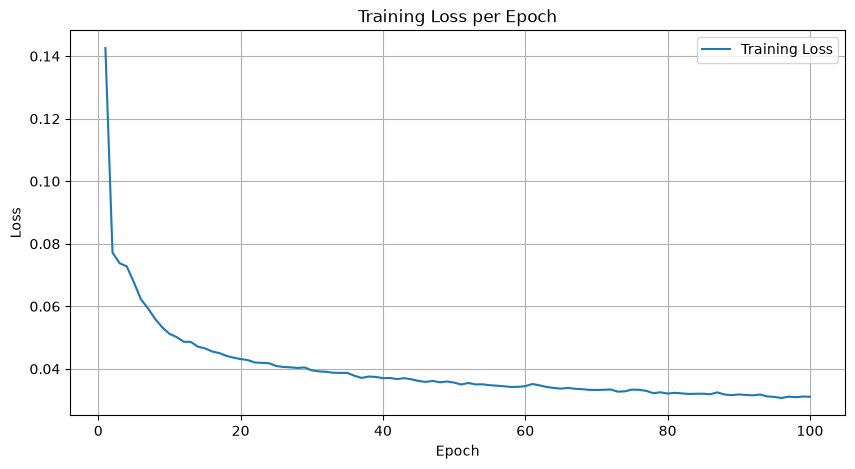

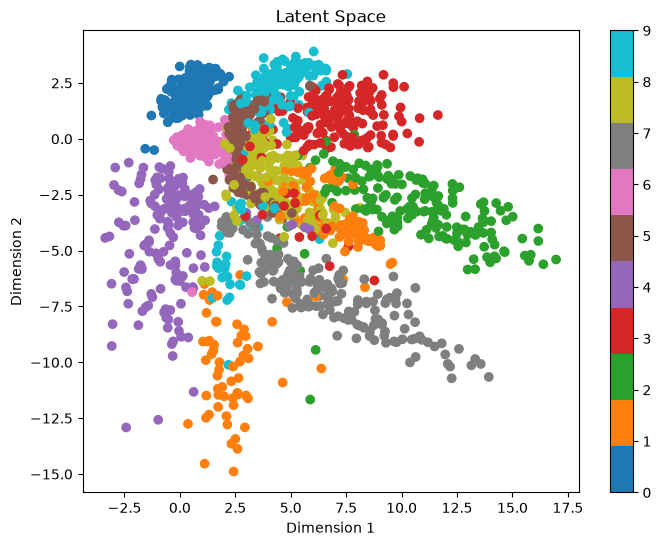

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
# from torchvision import transforms
from sklearn.datasets import load_digits
from torch.utils.data import DataLoader, TensorDataset
import random
import numpy as np


seed = 42
random.seed(seed)
np.random.seed(seed)

# データをロードします
digits = load_digits()
data = digits.data
targets = digits.target

# データを正規化します
data = data / 16.0  # 0-16までの整数値なので16で割って正規化

# NumPy配列をPyTorchのテンソルに変換します
data = torch.tensor(data, dtype=torch.float32)
targets = torch.tensor(targets, dtype=torch.int64)

# TensorDatasetとDataLoaderを構築
dataset = TensorDataset(data, targets)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

# class Autoencoder(nn.Module):
#     def __init__(self, input_dim, hidden_dim, latent_dim):
#         super(Autoencoder, self).__init__()
#         # エンコーダー: 入力層 -> 隠れ層 -> 潜在層
#         self.encoder = nn.Sequential(
#             nn.Linear(input_dim, hidden_dim),
#             nn.ReLU(),
#             nn.Linear(hidden_dim, latent_dim)
#         )
#         # デコーダー: 潜在層 -> 隠れ層 -> 出力層
#         self.decoder = nn.Sequential(
#             nn.Linear(latent_dim, hidden_dim),
#             nn.ReLU(),
#             nn.Linear(hidden_dim, input_dim),
#             nn.Sigmoid()  # 出力を0-1に制限
#         )

#     def forward(self, x):
#         z = self.encoder(x)
#         x_reconstructed = self.decoder(z)
#         return x_reconstructed, z

class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, latent_dim):
        super(Autoencoder, self).__init__()
        # エンコーダー: 入力層 -> 隠れ層1 -> 隠れ層2 -> 潜在層
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.ReLU(),
            nn.Linear(hidden_dim1, hidden_dim2),  # 追加の隠れ層
            nn.ReLU(),
            nn.Linear(hidden_dim2, latent_dim)
        )
        # デコーダー: 潜在層 -> 隠れ層1 -> 隠れ層2 -> 出力層
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim2),
            nn.ReLU(),
            nn.Linear(hidden_dim2, hidden_dim1),  # 追加の隠れ層
            nn.ReLU(),
            nn.Linear(hidden_dim1, input_dim),
            nn.Sigmoid()  # 出力を0-1に制限
        )

    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        return x_reconstructed, z

input_dim = data.shape[1]  # 64 (8x8画像)
hidden_dim1 = 128        # 隠れ層の次元
hidden_dim2 = 64        # 隠れ層の次元

latent_dim = 2          # 潜在空間の次元

# モデル、損失関数、最適化手法の設定
model = Autoencoder(input_dim, hidden_dim1, hidden_dim2, latent_dim)
criterion = nn.MSELoss()  # 損失関数は平均二乗誤差
# criterion = nn.BCELoss()  # 損失関数はBCE

optimizer = optim.Adam(model.parameters(), lr=0.001)

# 学習を行います
num_epochs = 100

losses = []
for epoch in range(num_epochs):
    epoch_loss = 0
    for batch_data, _ in dataloader:
        # モデルを訓練モードに設定
        model.train()
        
        # 順伝播
        reconstructed, _ = model(batch_data)
        loss = criterion(reconstructed, batch_data)
        
        # 逆伝播と最適化
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # バッチの損失をエポックの総損失に加算
        epoch_loss += loss.item()
    
    # エポックごとに損失を記録
    average_loss = epoch_loss / len(dataloader)
    losses.append(average_loss)
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {average_loss:.4f}')



import matplotlib.pyplot as plt

# 損失のプロット
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss per Epoch')
plt.legend()
plt.grid(True)
plt.show()

# 全データを用いて潜在変数を取得
model.eval()
with torch.no_grad():
    _, latent_space = model(data)

# 2次元潜在空間をプロット
latent_space = latent_space.numpy()
plt.figure(figsize=(8, 6))
plt.scatter(latent_space[:, 0], latent_space[:, 1], c=targets, cmap='tab10')
plt.colorbar()
plt.title('Latent Space')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.show()

上の図は二次元潜在空間を示す。

## 再構成した画像との比較

どの程度元画像に戻るのかを表示させる。

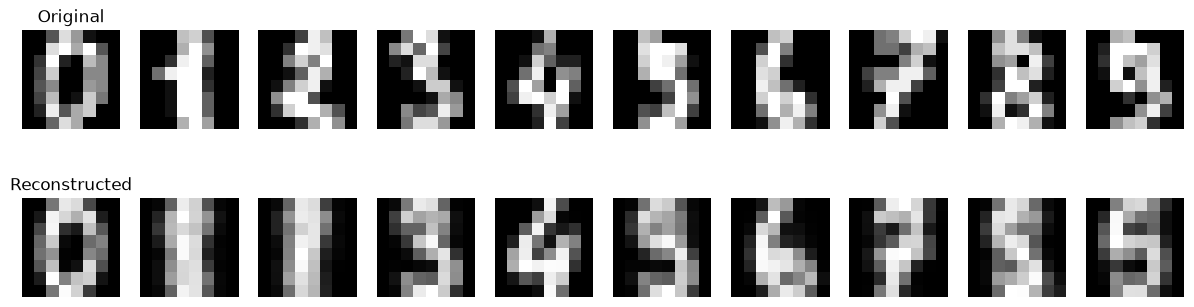

In [4]:
import matplotlib.pyplot as plt

# 訓練済みモデルを評価モードに切り替え
model.eval()

# 入力データをモデルに通して再構成を取得
with torch.no_grad():
    reconstructed_data, _ = model(data)

# Tensor を numpy array に変換
input_data_np = data.numpy()
reconstructed_data_np = reconstructed_data.numpy()

# 比較するための画像数を設定
num_images_to_show = 10  # 例えば最初の10個を表示

# 図示
fig, axes = plt.subplots(nrows=2, ncols=num_images_to_show, figsize=(15, 4))
for i in range(num_images_to_show):
    # 入力画像
    axes[0, i].imshow(input_data_np[i].reshape(8, 8), cmap='gray')
    axes[0, i].axis('off')
    
    # 再構成画像
    axes[1, i].imshow(reconstructed_data_np[i].reshape(8, 8), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_title("Original", fontsize=12)
axes[1, 0].set_title("Reconstructed", fontsize=12)

plt.show()

## 二次元潜在空間に対応する画像

次に、二次元潜在空間の図の範囲を５０％拡張し、各軸１０分割して、対応する画像を並べてた。


In [5]:
import numpy as np

factor = 0.5

ptp = np.ptp(latent_space, axis=0)

(x1, y1), (x2, y2) = (
    latent_space.min(axis=0) - ptp * factor,
    latent_space.max(axis=0) + ptp * factor
)

print("xrange", x1, x2)
print("yrange", y1, y2)


xrange -13.537441 27.134281
yrange -24.280113 13.303637


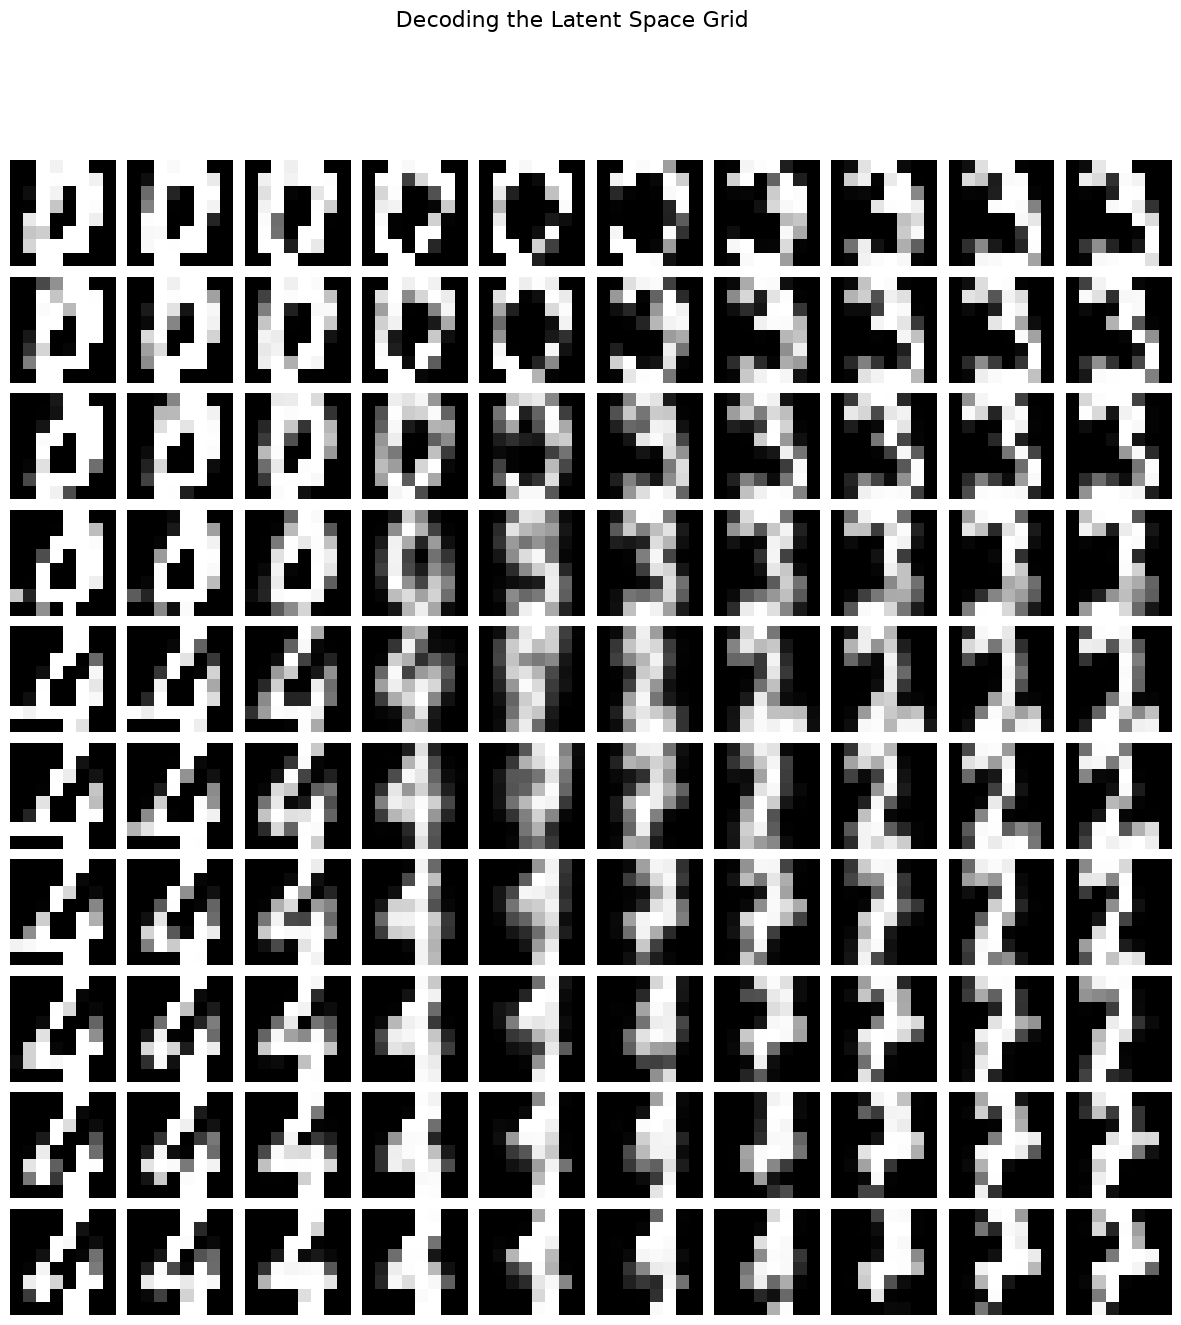

In [6]:
import numpy as np

# 潜在空間を10x10のグリッドに分割
x_range = (x1, x2)
y_range = (y2, y1)

# 分割数
n_bins = 10

# 潜在空間を10x10のグリッドに分割
fig, axarr = plt.subplots(n_bins, n_bins, figsize=(15, 15))

x_bins = np.linspace(x_range[0], x_range[1], n_bins)
y_bins = np.linspace(y_range[0], y_range[1], n_bins)

# 各グリッドに対応する潜在コードからデコードされた各画像を表示
for i, x_val in enumerate(x_bins):
    for j, y_val in enumerate(y_bins):
        # 選ばれた潜在変数のグリッドでの座標
        z = torch.tensor([[x_val, y_val]], dtype=torch.float32)

        # デコードして画像を生成
        with torch.no_grad():
            generated = model.decoder(z).numpy().reshape(8, 8)

        # 画像をプロット
        axarr[j, i].imshow(generated, cmap='gray')
        axarr[j, i].axis('off')

plt.suptitle('Decoding the Latent Space Grid', fontsize=16)
plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.show()

## LLMによるコードの説明

### prompt
```prompt
コードをブロックごとに説明してください
```

![](fig/8200-autoencoder-code-explain1.png)


LLMは値の範囲が0から16であることを知っていて規格化している。


### LLMによる説明

gpt-4oが作った最初のモデルは以下の通り。

![](fig/8200-autoencoder-code-explain2.png)


networkは全結合NNです。

![](fig/8200-autoencoder-network.jpg)


![](fig/8200-autoencoder-code-explain3.png)

![](fig/8200-autoencoder-code-explain4.jpg)

上の説明で訓練データのバッチごとにのloopが赤く書いている。

![](fig/8200-autoencoder-code-explain5.jpg)


## 損失関数

### prompt
```prompt
"""
        loss = criterion(reconstructed, batch_data)
"""
部分が何を比較しているのかを教えてください。
```

### answer

batch_data: 元々の入力データ
Reconstructed: オートエンコーダーが復元したデータ

criterion = nn.MSELoss()
と定義したので、

元々の入力データとオートエンコーダーが復元したデータの差をMSEで評価した。

![](fig/8200-autoencoder-code-explain6.jpg )


## Dataloader

dataloaderは何をしているのだろうか。


### prompt
```prompt
「データローダからデータをバッチごとに取り出し、」の部分をもっと詳しく教えてください。
```

![](fig/8200-autoencoder-code-dataloader1.png)

参照文献：https://pytorch.org/docs/stable/data.html


![](fig/8200-autoencoder-code-dataloader2.jpg)

## コメント
Scikit-learnの手書き文字の画像が8x8サイズであること、0-16までの値を持つことをgpt-4oが知っていました。（それもあり、指定が簡単になるので Scikit-learnの手書き文字を使っています。）ユーザー画像を用いる場合は縦横サイズ、値が、0－255までであることなど、をプロンプトに付け加えると適切なpreprocessをしてくれるでしょう。


例ではChatGPTは全結合ニューラルネットワークモデルを作成しましたが、畳み込みニューラルネットワークや（有名ならば）〇〇Netという指定も可能です。畳み込みニューラルネットワークを用いても画像サイズにより妥当なネットワークは異なります。

